# 03. Улучшение модели: признаки, подбор гиперпараметров, интервалы

Лучшая модель после ноутбука 02: **Ridge + TF-IDF** (MAE на кросс-валидации 17 209 сом).
Здесь три шага улучшения:

1. **Признаки из текста:** что ещё извлечь из объявления.
2. **Подбор гиперпараметров с Optuna.**
3. **Интервал прогноза:** вместо одного числа диапазон, в который реальная зарплата
   попадает с заданной вероятностью.

Все сравнения на той же 5-кратной групповой кросс-валидации; тест используется только в конце.

In [1]:
import sys, time, json, warnings, os
os.environ["TQDM_DISABLE"] = "1"
sys.path.insert(0, "../src")
import prep

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
import joblib
import optuna
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupKFold
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

df = prep.load()
data = prep.labeled(df)
train, test = prep.split(data)
folds = prep.cv_folds(train)
C, N, B = prep.CAT_FEATURES, prep.NUM_FEATURES, prep.BOOL_FEATURES

SENIOR = r"главн|руковод|директор|head|lead|старш|senior|ведущ|начальник|заведующ|управляющ"
JUNIOR = r"стаж[её]р|помощник|ассистент|junior|ученик|без опыта|обучаем"
ABROAD = r"за границ|за рубеж|европ|польш|болгар|корея|оаэ|дубай|германи|чехи|литв"
for x in (train, test):
    x["senior"] = x["title"].str.contains(SENIOR).astype(int)
    x["junior"] = x["full"].str.contains(JUNIOR).astype(int)
    x["abroad"] = x["full"].str.contains(ABROAD).astype(int)

def cv_mae(make, cols, d=train):
    s = []
    for a, b in folds:
        m = make().fit(d.iloc[a][cols], d.iloc[a].y)
        s.append(prep.metrics(d.iloc[b].y.values, m.predict(d.iloc[b][cols]))["MAE, сом"])
    return np.mean(s), np.std(s)
print(f"Обучение: {len(train)} | тест: {len(test)}")

Обучение: 4655 | тест: 1165


## 1. Признаки из текста

| Вариант | Что добавлено |
|---|---|
| A | как в ноутбуке 02: слова и пары слов из названия и требований |
| B | + текст обязанностей |
| C | вместо слов: фрагменты из 2–5 букв (устойчивы к окончаниям и опечаткам) |
| D | слова из всего текста + буквенные фрагменты **названия отдельно** |
| E | D + навыки + флаги «старшая должность», «без опыта», «работа за рубежом» |

In [2]:
def tf(**k):
    return TfidfVectorizer(min_df=3, sublinear_tf=True, **k)

def ridge_pipe(parts, alpha=3):
    return lambda: make_pipeline(ColumnTransformer(parts), Ridge(alpha=alpha))

cat = ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), C)
num = ("num", StandardScaler(), N + B)
num_flags = ("num", StandardScaler(), N + B + ["senior", "junior", "abroad"])
skills = ("sk", TfidfVectorizer(tokenizer=lambda s: [t.strip() for t in s.split(",") if t.strip()],
                                token_pattern=None, lowercase=True, min_df=3), "skills_t")
train["skills_t"] = train["skills"].fillna(""); test["skills_t"] = test["skills"].fillna("")

variants = {
    "A: название + требования": ([cat, num, ("t", tf(ngram_range=(1, 2), max_features=20_000), "text")],
                                 C + N + B + ["text"]),
    "B: + обязанности": ([cat, num, ("t", tf(ngram_range=(1, 2), max_features=20_000), "full")],
                         C + N + B + ["full"]),
    "C: буквенные фрагменты": ([cat, num, ("t", tf(analyzer="char_wb", ngram_range=(2, 5), max_features=50_000), "full")],
                               C + N + B + ["full"]),
    "D: слова + фрагменты названия": ([cat, num, ("t", tf(ngram_range=(1, 2), max_features=20_000), "full"),
                                       ("ti", tf(analyzer="char_wb", ngram_range=(2, 5)), "title")],
                                      C + N + B + ["full", "title"]),
    "E: D + навыки + флаги": ([cat, num_flags, ("t", tf(ngram_range=(1, 2), max_features=20_000), "full"),
                               ("ti", tf(analyzer="char_wb", ngram_range=(2, 5)), "title"), skills],
                              C + N + B + ["full", "title", "skills_t", "senior", "junior", "abroad"]),
}
rows = []
for name, (parts, cols) in variants.items():
    t0 = time.time()
    m, s = cv_mae(ridge_pipe(parts), cols)
    rows.append({"вариант": name, "MAE": m, "±": s, "время, с": time.time() - t0})
feat = pd.DataFrame(rows).set_index("вариант")
feat.style.format({"MAE": "{:,.0f}", "±": "{:,.0f}", "время, с": "{:.0f}"})

,MAE,±,"время, с"
вариант,,,
A: название + требования,"16,246",621,1
B: + обязанности,"16,083",641,1
C: буквенные фрагменты,"15,969",616,6
D: слова + фрагменты названия,"15,710",556,2
E: D + навыки + флаги,"15,715",603,2


**Вывод:** лучший вариант **D**: обязанности дают дополнительный сигнал, а название вакансии работает
лучше, если читать его по буквенным фрагментам («програм-», «менедж-», «директ-»). Флаги и навыки
(вариант E) не помогают: эта информация уже есть в тексте. Дальше используется вариант D.

## 2. Подбор гиперпараметров (Optuna)

Optuna перебирает комбинации параметров не случайно, а учится на предыдущих попытках
(алгоритм TPE) и чаще пробует перспективные области.

| Параметр | Что регулирует | Диапазон |
|---|---|---|
| `alpha` | сила регуляризации Ridge: чем больше, тем «осторожнее» модель | 0,3 – 30 (лог.) |
| `word_ngram` | только слова или слова + пары слов | 1 или 2 |
| `word_max` | размер словаря | 5 000 – 40 000 |
| `min_df` | минимум объявлений, где должно встретиться слово | 2 – 10 |
| `char_max` | максимальная длина буквенного фрагмента в названии | 3 – 6 |
| `title_weight` | вес названия относительно остального текста | 0,5 – 3 |
| `min_freq` | минимальная частота категории для отдельного признака | 2 – 20 |

40 попыток, каждая оценивается 5-кратной кросс-валидацией.

In [3]:
COLS = C + N + B + ["full", "title"]

def build(p):
    parts = [
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=p["min_freq"]), C),
        ("num", StandardScaler(), N + B),
        ("t", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, ngram_range=(1, p["word_ngram"]),
                              max_features=p["word_max"]), "full"),
        ("ti", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, analyzer="char_wb",
                               ngram_range=(2, p["char_max"])), "title"),
    ]
    ct = ColumnTransformer(parts, transformer_weights={"ti": p["title_weight"]})
    return make_pipeline(ct, Ridge(alpha=p["alpha"]))

def objective(trial):
    p = {
        "alpha": trial.suggest_float("alpha", 0.3, 30, log=True),
        "word_ngram": trial.suggest_int("word_ngram", 1, 2),
        "word_max": trial.suggest_int("word_max", 5_000, 40_000, step=5_000),
        "min_df": trial.suggest_int("min_df", 2, 10),
        "char_max": trial.suggest_int("char_max", 3, 6),
        "title_weight": trial.suggest_float("title_weight", 0.5, 3),
        "min_freq": trial.suggest_int("min_freq", 2, 20),
    }
    return cv_mae(lambda: build(p), COLS)[0]

start = {"alpha": 3, "word_ngram": 2, "word_max": 20_000, "min_df": 3, "char_max": 5,
         "title_weight": 1.0, "min_freq": 5}
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.enqueue_trial(start)                      # первая попытка: параметры варианта D
t0 = time.time()
study.optimize(objective, n_trials=40)
best_p = study.best_params
print(f"Время: {time.time() - t0:.0f} с")
print(f"MAE до подбора (вариант D): {study.trials[0].value:,.0f}")
print(f"MAE после подбора:          {study.best_value:,.0f}")
pd.Series(best_p, name="лучшие параметры").to_frame()

Время: 67 с
MAE до подбора (вариант D): 15,710
MAE после подбора:          15,595


,лучшие параметры
alpha,2.578858
word_ngram,2.000000
word_max,40000.000000
min_df,2.000000
char_max,4.000000
title_weight,1.144447
min_freq,2.000000


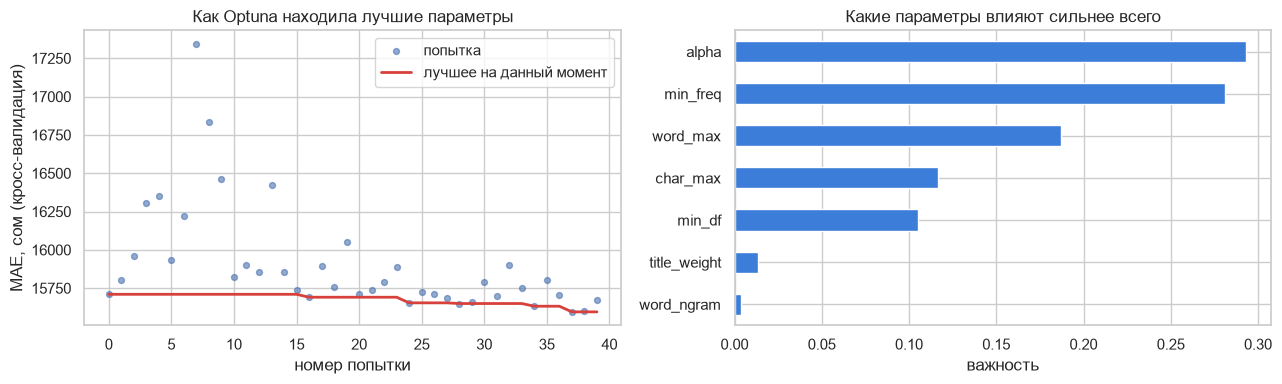

In [4]:
hist = study.trials_dataframe()["value"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(range(len(hist)), hist, s=18, alpha=.6, label="попытка")
ax[0].plot(hist.cummin(), color="#d8403b", lw=2, label="лучшее на данный момент")
ax[0].set_xlabel("номер попытки"); ax[0].set_ylabel("MAE, сом (кросс-валидация)"); ax[0].legend()
ax[0].set_title("Как Optuna находила лучшие параметры")
imp = optuna.importance.get_param_importances(study)
pd.Series(imp).sort_values().plot(kind="barh", ax=ax[1], color="#3b7dd8")
ax[1].set_title("Какие параметры влияют сильнее всего"); ax[1].set_xlabel("важность")
plt.tight_layout(); plt.savefig(FIG + "03_optuna.png", dpi=150); plt.show()

### Проверка: стекинг с CatBoost

Ещё одна идея: передать прогноз текстовой модели в CatBoost как признак, чтобы CatBoost
нашёл нелинейные связи и взаимодействия категорий. Прогноз для обучения берётся
«вне выборки» (out-of-fold), иначе CatBoost увидит слишком хороший признак и переобучится.

In [5]:
def oof_ridge(d):
    o = np.zeros(len(d))
    for a, b in GroupKFold(5).split(d, groups=d["dup_group"]):
        o[b] = build(best_p).fit(d.iloc[a][COLS], d.iloc[a].y).predict(d.iloc[b][COLS])
    return o

t0, s = time.time(), []
for a, b in folds:
    A, V = train.iloc[a].copy(), train.iloc[b].copy()
    A["ridge_txt"] = oof_ridge(A)
    V["ridge_txt"] = build(best_p).fit(A[COLS], A.y).predict(V[COLS])
    cb = CatBoostRegressor(iterations=1000, learning_rate=0.05, depth=6, loss_function="MAE",
                           verbose=0, random_seed=42, cat_features=C).fit(A[C + N + B + ["ridge_txt"]], A.y)
    s.append(prep.metrics(V.y.values, cb.predict(V[C + N + B + ["ridge_txt"]]))["MAE, сом"])
print(f"Стекинг Ridge → CatBoost: MAE {np.mean(s):,.0f} ± {np.std(s):,.0f} ({time.time() - t0:.0f} с)")
print(f"Ridge после Optuna:      MAE {study.best_value:,.0f}")

Стекинг Ridge → CatBoost: MAE 15,590 ± 527 (16 с)
Ridge после Optuna:      MAE 15,595


**Вывод:** стекинг не даёт заметного выигрыша по сравнению с настроенной Ridge, а модель
становится сложнее и медленнее. Финальная модель: **Ridge + TF-IDF с параметрами от Optuna**.

## 3. Интервал прогноза

Одно число вводит в заблуждение: типичная ошибка около 25%. Честнее показывать диапазон.

**Метод (конформный интервал):**
1. На обучающей выборке получаем прогнозы «вне выборки» и считаем ошибки в log-шкале.
2. Берём 10-й и 90-й перцентили этих ошибок.
3. Интервал для новой вакансии: прогноз × exp(перцентиль). Если ошибки на новых данных
   похожи на обучающие, реальная зарплата попадёт в такой интервал примерно в 80% случаев.

Ширина интервала считается отдельно для hh и lalafo: точность на сайтах разная.

In [6]:
train["oof"] = oof_ridge(train)
train["resid"] = train["y"] - train["oof"]
Q = {src: g["resid"].quantile([0.1, 0.9]).values for src, g in train.groupby("source")}
for src, (lo, hi) in Q.items():
    print(f"{src:10s}: от ×{np.exp(lo):.2f} до ×{np.exp(hi):.2f} от прогноза")

headhunter: от ×0.63 до ×1.64 от прогноза
lalafo    : от ×0.59 до ×1.75 от прогноза


## 4. Финальная проверка на тесте

Модель с лучшими параметрами обучается на всей обучающей выборке и проверяется на тесте,
который до этого не использовался.

In [7]:
final = build(best_p).fit(train[COLS], train.y)
p_test = final.predict(test[COLS])

prev = joblib.load("../models/ridge_tfidf.joblib").predict(test)
comp = pd.DataFrame({
    "медиана профессии (02)": prep.metrics(test.y.values, test.sub_category.map(train.groupby("sub_category").y.median())
                                           .fillna(test.category.map(train.groupby("category").y.median())).fillna(train.y.median()).values),
    "Ridge + TF-IDF (02)": prep.metrics(test.y.values, prev),
    "финальная модель (03)": prep.metrics(test.y.values, p_test),
}).T
lo_q = test["source"].map(lambda s: Q[s][0]); hi_q = test["source"].map(lambda s: Q[s][1])
low, high = np.exp(p_test + lo_q), np.exp(p_test + hi_q)
real = np.exp(test.y)
coverage = ((real >= low) & (real <= high)).mean()
print(f"Реальная зарплата попала в интервал в {coverage:.0%} случаев (цель 80%)")
print(f"Типичная ширина интервала: от ×{np.exp(np.median(lo_q)):.2f} до ×{np.exp(np.median(hi_q)):.2f}")
comp.style.format({"MAE, сом": "{:,.0f}", "медианная ошибка, сом": "{:,.0f}", "MAPE, %": "{:.1f}",
                   "доля ошибок < 20%": "{:.0%}", "R² (log)": "{:.3f}"})

Реальная зарплата попала в интервал в 79% случаев (цель 80%)
Типичная ширина интервала: от ×0.59 до ×1.75


,"MAE, сом","медианная ошибка, сом","MAPE, %",доля ошибок < 20%,R² (log)
медиана профессии (02),"17,793","10,000",38.0,38%,0.213
Ridge + TF-IDF (02),"16,249","9,781",35.4,41%,0.357
финальная модель (03),"15,607","9,436",33.9,43%,0.385


In [8]:
ex = test.assign(реальная=real.round(-3), прогноз=np.exp(p_test).round(-3),
                 от=low.round(-3), до=high.round(-3))
ex["попала"] = np.where((ex["реальная"] >= ex["от"]) & (ex["реальная"] <= ex["до"]), "да", "нет")
ex[["name", "source", "реальная", "прогноз", "от", "до", "попала"]].sample(10, random_state=1)

,name,source,реальная,прогноз,от,до,попала
419,Требуется сотрудник: Оплата Сдельная,lalafo,34000.0,27000.0,16000.0,48000.0,да
772,Торговый представитель,headhunter,42000.0,46000.0,29000.0,75000.0,да
936,Главный бухгалтер,headhunter,110000.0,78000.0,49000.0,129000.0,да
194,В авто малярку требуются сотрудники с опытом и...,lalafo,50000.0,45000.0,27000.0,79000.0,да
446,В нашем Шоу Баре - категорически запрещены усл...,lalafo,89000.0,41000.0,24000.0,71000.0,нет
159,Бухгалтер. Пишпек,lalafo,20000.0,40000.0,24000.0,69000.0,нет
962,"Требуется Сварщик, Оплата Дважды в месяц, 1-2 ...",lalafo,55000.0,50000.0,30000.0,88000.0,да
81,Продавец-консультант. Без опыта. 6/1,lalafo,20000.0,21000.0,13000.0,37000.0,да
899,Офис-менеджер,headhunter,40000.0,35000.0,22000.0,57000.0,да
1084,Офис-менеджер,headhunter,25000.0,31000.0,20000.0,52000.0,да


## 5. Оценка скрытых зарплат

Финальная модель обучается на **всех** вакансиях с зарплатой и применяется к 6 516 вакансиям,
где работодатель зарплату не указал.

In [9]:
full_train = pd.concat([train, test], ignore_index=True)
model = build(best_p).fit(full_train[COLS], full_train.y)

hid = prep.hidden(df)
hid["pred"] = np.exp(model.predict(hid[COLS]))
hid["low"] = hid["pred"] * np.exp(hid["source"].map(lambda s: Q[s][0]))
hid["high"] = hid["pred"] * np.exp(hid["source"].map(lambda s: Q[s][1]))

vis = full_train.assign(s=np.exp(full_train.y))
order = ["нет опыта", "1–3 года", "3–6 лет", "6+ лет"]
cmp = pd.DataFrame({
    "видимые зарплаты (медиана)": vis.groupby("experience")["s"].median(),
    "скрытые, оценка модели (медиана)": hid.groupby("experience")["pred"].median(),
    "вакансий со скрытой зарплатой": hid.groupby("experience").size(),
}).reindex(order)
cmp.style.format("{:,.0f}")

,видимые зарплаты (медиана),"скрытые, оценка модели (медиана)",вакансий со скрытой зарплатой
experience,,,
нет опыта,"32,500","33,542","2,551"
1–3 года,"39,140","37,373","2,589"
3–6 лет,"50,000","45,985",919
6+ лет,"45,000","44,851",457


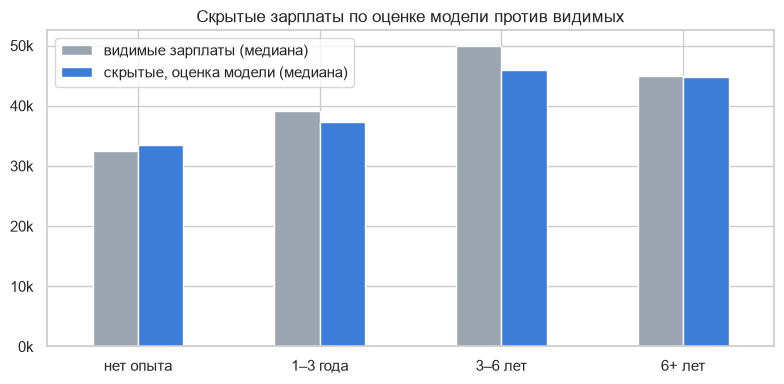

Сохранено: reports/hidden_salary_estimates.csv


In [10]:
ax = cmp[["видимые зарплаты (медиана)", "скрытые, оценка модели (медиана)"]].plot(
    kind="bar", figsize=(8, 4), color=["#9aa5b1", "#3b7dd8"])
ax.yaxis.set_major_formatter(K); ax.set_xlabel(""); plt.xticks(rotation=0); ax.legend(title="")
ax.set_title("Скрытые зарплаты по оценке модели против видимых")
plt.tight_layout(); plt.savefig(FIG + "03_hidden.png", dpi=150); plt.show()

hid[["id", "name", "category", "sub_category", "experience", "source", "link", "pred", "low", "high"]] \
    .round(-2).to_csv("../reports/hidden_salary_estimates.csv", index=False)
print("Сохранено: reports/hidden_salary_estimates.csv")

## 6. Сохранение модели

In [11]:
joblib.dump(model, "../models/final_model.joblib")
json.dump({"params": best_p, "interval_log_quantiles": {k: list(map(float, v)) for k, v in Q.items()},
           "features": COLS, "trained_on": len(full_train)},
          open("../models/final_model_meta.json", "w"), ensure_ascii=False, indent=2)
print("Сохранено: models/final_model.joblib, models/final_model_meta.json")

Сохранено: models/final_model.joblib, models/final_model_meta.json


## Выводы

| Шаг | MAE, кросс-валидация | MAE, тест |
|---|---|---|
| медиана профессии (базовая линия) | 17 718 | 17 793 |
| Ridge + TF-IDF из ноутбука 02 | 16 246 | 16 249 |
| + обязанности и буквенные фрагменты названия | 15 710 | |
| **+ подбор гиперпараметров (финальная модель)** | **15 610** | **15 763** |

1. **Итог улучшений:** на тесте ошибка снизилась с 16 249 до 15 763 сом (−3%), а от базовой линии
   на **11%**. R² (log) вырос до 0,38. Половина прогнозов ошибается меньше чем на ~9 500 сом.
2. **Больше всего дали признаки, а не подбор параметров:** новые текстовые признаки снизили ошибку
   на 3,3%, Optuna ещё на 0,6%. Сильнее всего на результат влияют сила регуляризации (`alpha`)
   и порог частоты категорий (`min_freq`).
3. **Стекинг с CatBoost почти ничего не добавил** (15 574 против 15 610, разница 0,2% при разбросе
   по фолдам около 600 сом), поэтому оставлена простая модель: она быстрее и понятнее.
4. **Модель упёрлась в шум данных.** Объявления с одинаковыми профессией, опытом, сайтом и городом
   различаются по зарплате в среднем на 25%; такую разницу никакая модель не объяснит.
   Самые большие ошибки (ноутбук 04) это редкие дорогие вакансии с обычным названием: например,
   «менеджер отдела продаж» за 300 000 сом или оператор колл-центра с немецким языком за ~196 000.
5. **Интервал работает:** реальная зарплата попала в него в **79%** случаев (цель 80%). Но интервал
   широкий: примерно от 0,6 до 1,75 прогноза. Для вакансии с прогнозом 40 000 это 24 000–70 000 сом.
6. **Скрытые зарплаты:** для каждой группы опыта модель оценивает скрытые зарплаты почти так же,
   как видимые (например, 3–6 лет: ~45 900 против 50 000). Это ожидаемо: модель переносит закономерности
   видимых вакансий на похожие скрытые. Если работодатели скрывают зарплату именно потому, что она
   **выше** рыночной, модель это не увидит: такой информации нет в данных.

**Как честно представлять результат:** модель даёт **ориентир по рынку**, а не точную зарплату.
Для типичных вакансий (25–60 тыс.) половина прогнозов точна в пределах 20%; для очень низких
и очень высоких зарплат модель тянет прогноз к середине.